<a href="https://colab.research.google.com/github/Mutisojr34/SemProject_MLEngine/blob/main/KMeans_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ICS 3202: Artificial Intelligence
Project Deliverable 2 (CAT 2)

# 1. Research Problem and Machine Learning Approach

## 1.1 Research Problem

UniPool is a proposed ride-pooling mobile application for Strathmore University students. It aims to help students travelling in similar directions share rides. For this deliverable, a sample ride dataset is used to investigate whether machine learning can predict the recorded status of a trip.

The prediction problem is to classify each trip into one of three categories: **Completed, Cancelled, or No-Show**. This experiment provides an opportunity to explore the dataset, train classification models, and evaluate their performance.

## 1.2 Selected Machine Learning Approach

This project uses **supervised machine learning classification** because the dataset contains a target variable, `status`, with predefined categories.

The initial models investigated are:

- **Baseline classifier:** provides a reference for comparing model performance.
- **Decision Tree classifier:** learns decision rules from the available trip features.
- **Random Forest classifier:** combines multiple decision trees to produce predictions.

The input features include pickup time information, pickup and drop-off coordinates, payment method, trip distance, and fare amount. The target variable is `status`.

## 1.3 Scope and Limitations

This experiment predicts historical trip status; it does not directly determine whether two students are suitable ride-pooling partners. The dataset does not contain an explicit ride-compatibility label. In addition, the exploratory analysis identified potential inconsistencies between city labels and geographic coordinates.

Consequently, the results should be interpreted as a preliminary classification experiment rather than evidence that UniPool can already match students successfully. A future ride-pooling model would require suitable data about passengers' origins, destinations, travel times, and confirmed ride-sharing compatibility.

1. Importing required libraries


In [1]:
# Import pandas for working with datasets
import pandas as pd

In [2]:
# Import NumPy for numerical operations
import numpy as np


In [3]:
# Import matplotlib for creating graphs
import matplotlib.pyplot as plt


In [4]:
# Import KMeans for clustering
from sklearn.cluster import KMeans

In [6]:
# Import StandardScaler for scaling numerical features
from sklearn.preprocessing import StandardScaler

In [7]:
# Import silhouette_score for evaluating clusters
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


# 2. Data Exploration and Cleaning

## 2.1 Dataset Overview

The dataset contains 6,049 trip records and 14 original columns. These include trip identifiers, driver and rider identifiers, city, pickup and drop-off coordinates, trip distance, fare amount, trip status, payment method, and pickup and drop-off times.

## 2.2 Data Quality Checks

The following checks were performed during data exploration:

- **Missing values:** No missing values were identified in the dataset.
- **Duplicate records:** No duplicate rows or duplicate trip identifiers were found.
- **Data types:** The pickup and drop-off time columns were represented as datetime values, while numerical and categorical columns retained their appropriate data types.
- **Trip duration:** Trip duration was calculated from the pickup and drop-off timestamps. No negative durations were identified, although some trips had unusually short durations that may require further investigation.
- **Distance and fare:** No non-positive trip distances or fare amounts were found.
- **Geographic consistency:** The city labels appeared inconsistent with the pickup coordinates. This is an important data-quality limitation, particularly for models that rely on geographic location.

## 2.3 Preparation for Modelling

The pickup timestamp was used to derive `pickup_hour` and `pickup_day`. These features represent the hour and day of the week when a trip started.

The `status` column was selected as the target variable, with three classes: Completed, Cancelled, and No-Show. The selected input features included pickup time information, pickup and drop-off coordinates, payment method, distance, and fare.

Categorical payment-method values were converted into numerical indicator features using one-hot encoding. The data was split into training and testing sets using an 80:20 ratio, with stratification to preserve the proportions of the target classes.

## 2.4 Data Cleaning Limitations

Although the dataset passed several basic quality checks, the geographic inconsistency suggests that not all values should automatically be considered reliable. The unusually short trip durations also warrant investigation.

These limitations are documented rather than assumed to have been fully resolved. The resulting model performance must therefore be interpreted cautiously.



Process of uploading


In [9]:

from google.colab import files

uploaded = files.upload()


Saving uber_trips_dataset_50k.csv.xlsx to uber_trips_dataset_50k.csv.xlsx


In [10]:
# Load the uploaded Excel file
df = pd.read_excel("uber_trips_dataset_50k.csv.xlsx")

In [11]:
# Display the dataset size
print("Dataset shape:", df.shape)

Dataset shape: (6049, 14)


In [12]:
# Display the first five records
df.head()


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01 00:00:00,2023-01-01 00:08:55
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01 00:01:00,2023-01-01 00:26:17
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01 00:02:00,2023-01-01 00:18:23
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01 00:03:00,2023-01-01 00:22:50
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01 00:04:00,2023-01-01 00:35:30


In [13]:
# Check column names and data types
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6049 entries, 0 to 6048
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   trip_id         6049 non-null   int64         
 1   driver_id       6049 non-null   int64         
 2   rider_id        6049 non-null   int64         
 3   city            6049 non-null   object        
 4   pickup_lat      6049 non-null   float64       
 5   pickup_lng      6049 non-null   float64       
 6   drop_lat        6049 non-null   float64       
 7   drop_lng        6049 non-null   float64       
 8   distance_km     6049 non-null   float64       
 9   fare_amount     6049 non-null   float64       
 10  status          6049 non-null   object        
 11  payment_method  6049 non-null   object        
 12  pickup_time     6049 non-null   datetime64[ns]
 13  drop_time       6049 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(6), 

In [14]:
# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
trip_id           0
driver_id         0
rider_id          0
city              0
pickup_lat        0
pickup_lng        0
drop_lat          0
drop_lng          0
distance_km       0
fare_amount       0
status            0
payment_method    0
pickup_time       0
drop_time         0
dtype: int64


4. Select the features for clustering


In [15]:
# Select the location features for clustering
features = [
    "pickup_lat",
    "pickup_lng",
    "drop_lat",
    "drop_lng"
]

In [16]:
# Create a separate dataset containing only these features
X = df[features].copy()

In [17]:
# Display the first five rows
print("Selected features:")
display(X.head())

Selected features:


,pickup_lat,pickup_lng,drop_lat,drop_lng
0,37.170931,-77.586479,37.173652,-77.619934
1,38.898127,-108.582977,38.937464,-108.558727
2,38.814571,-89.942603,38.821702,-89.896435
3,37.295906,-75.328844,37.301375,-75.317488
4,38.972395,-121.482913,38.992088,-121.467904


In [18]:
# Check the size of the feature dataset
print("\nFeature dataset shape:", X.shape)


Feature dataset shape: (6049, 4)


5. We decided to cluster trips within the same city rather that risking grouping unrelated trips together


In [19]:
# Count trips in each city
print("Trips per city:")
print(df["city"].value_counts())

Trips per city:
city
Boston           1058
Los Angeles      1035
Chicago          1010
Seattle           993
San Francisco     981
New York          972
Name: count, dtype: int64


In [20]:
# Check the number of unique cities
print("\nNumber of cities:", df["city"].nunique())


Number of cities: 6


6. we Selected boston


In [21]:
# Select trips from Boston only
selected_city = "Boston"

city_df = df[df["city"] == selected_city].copy()

In [22]:
# Select the pickup and drop-off coordinates
features = ["pickup_lat", "pickup_lng", "drop_lat", "drop_lng"]
X_city = city_df[features].copy()


In [23]:
# Display the results
print("Selected city:", selected_city)
print("Number of trips:", len(city_df))
print("Feature dataset shape:", X_city.shape)

display(X_city.head())

Selected city: Boston
Number of trips: 1058
Feature dataset shape: (1058, 4)


,pickup_lat,pickup_lng,drop_lat,drop_lng
1,38.898127,-108.582977,38.937464,-108.558727
9,40.712634,-78.499656,40.670267,-78.477475
11,40.374329,-107.843563,40.377110,-107.878868
12,38.996903,-111.387730,39.014518,-111.430031
17,38.896451,-115.984297,38.860639,-116.028525


7. Checking whether Boston's Co-ordinates are consistent to avoid misleading results


In [24]:
# Check the coordinate ranges for Boston trips
print("Pickup latitude range:")
print(city_df["pickup_lat"].min(), "to", city_df["pickup_lat"].max())

print("\nPickup longitude range:")
print(city_df["pickup_lng"].min(), "to", city_df["pickup_lng"].max())

print("\nSample of Boston trip coordinates:")
display(city_df[["pickup_lat", "pickup_lng", "drop_lat", "drop_lng"]].head(10))

Pickup latitude range:
37.00547752 to 40.99904835

Pickup longitude range:
-121.9648054 to -73.03789656

Sample of Boston trip coordinates:


,pickup_lat,pickup_lng,drop_lat,drop_lng
1,38.898127,-108.582977,38.937464,-108.558727
9,40.712634,-78.499656,40.670267,-78.477475
11,40.374329,-107.843563,40.377110,-107.878868
12,38.996903,-111.387730,39.014518,-111.430031
17,38.896451,-115.984297,38.860639,-116.028525
19,40.531085,-78.328683,40.510504,-78.292869
25,39.273950,-119.591948,39.230308,-119.577383
27,40.837628,-110.328737,40.850906,-110.315073
30,38.460721,-73.718838,38.451395,-73.676705
35,39.961944,-108.027548,39.982864,-108.063795


In [25]:
# Compare coordinate ranges across all cities
city_coordinates = df.groupby("city").agg(
    pickup_lat_min=("pickup_lat", "min"),
    pickup_lat_max=("pickup_lat", "max"),
    pickup_lng_min=("pickup_lng", "min"),
    pickup_lng_max=("pickup_lng", "max"),
    number_of_trips=("trip_id", "count")
)

display(city_coordinates)

,pickup_lat_min,pickup_lat_max,pickup_lng_min,pickup_lng_max,number_of_trips
city,,,,,
Boston,37.005478,40.999048,-121.964805,-73.037897,1058
Chicago,37.003386,40.994166,-121.998334,-73.030348,1010
Los Angeles,37.002350,40.999223,-121.999465,-73.042255,1035
New York,37.017677,40.993546,-121.991729,-73.043545,972
San Francisco,37.010832,40.993739,-121.914802,-73.023730,981
Seattle,37.005341,40.997226,-121.785399,-73.002322,993


In [26]:
# Calculate the average pickup coordinates for each city
city_centres = df.groupby("city").agg(
    average_latitude=("pickup_lat", "mean"),
    average_longitude=("pickup_lng", "mean"),
    number_of_trips=("trip_id", "count")
).round(4)

display(city_centres)

,average_latitude,average_longitude,number_of_trips
city,,,
Boston,39.0663,-97.7579,1058
Chicago,38.9802,-97.6410,1010
Los Angeles,38.9950,-97.5359,1035
New York,38.9716,-96.2597,972
San Francisco,38.9673,-96.7308,981
Seattle,38.9346,-96.1851,993


Checking what we can predict


In [27]:
# Examine the trip status categories
print("Trip status counts:")
print(df["status"].value_counts())

print("\nStatus percentages:")
print((df["status"].value_counts(normalize=True) * 100).round(2))

print("\nAvailable dataset columns:")
print(df.columns.tolist())

Trip status counts:
status
Completed    5143
Cancelled     601
No-Show       305
Name: count, dtype: int64

Status percentages:
status
Completed    85.02
Cancelled     9.94
No-Show       5.04
Name: proportion, dtype: float64

Available dataset columns:
['trip_id', 'driver_id', 'rider_id', 'city', 'pickup_lat', 'pickup_lng', 'drop_lat', 'drop_lng', 'distance_km', 'fare_amount', 'status', 'payment_method', 'pickup_time', 'drop_time']


Checking which features we can use safely

In [28]:
# Check how trip status relates to the available features
print("Trip status by payment method:")
display(pd.crosstab(df["payment_method"], df["status"]))

print("\nTrip status by city:")
display(pd.crosstab(df["city"], df["status"]))

print("\nPickup time range:")
print(df["pickup_time"].min(), "to", df["pickup_time"].max())

print("\nDrop time range:")
print(df["drop_time"].min(), "to", df["drop_time"].max())

Trip status by payment method:


status,Cancelled,Completed,No-Show
payment_method,,,
Card,153,1237,88
Cash,131,1276,70
UPI,166,1298,77
Wallet,151,1332,70



Trip status by city:


status,Cancelled,Completed,No-Show
city,,,
Boston,115,894,49
Chicago,102,844,64
Los Angeles,106,884,45
New York,81,850,41
San Francisco,111,807,63
Seattle,86,864,43



Pickup time range:
2023-01-01 00:00:00 to 2023-01-05 04:48:00

Drop time range:
2023-01-01 00:08:55 to 2023-01-05 05:23:46


Investigating distance and fare

In [29]:
# Compare distance and fare for each trip status
status_summary = df.groupby("status").agg(
    average_distance_km=("distance_km", "mean"),
    average_fare=("fare_amount", "mean"),
    median_distance_km=("distance_km", "median"),
    median_fare=("fare_amount", "median"),
    number_of_trips=("trip_id", "count")
).round(2)

display(status_summary)

,average_distance_km,average_fare,median_distance_km,median_fare,number_of_trips
status,,,,,
Cancelled,6.99,15.99,6.94,15.35,601
Completed,7.02,16.01,7.01,15.40,5143
No-Show,6.97,16.60,7.05,15.83,305


Check the dataset's time and status patterns

In [30]:
# Create a pickup-hour feature
df["pickup_hour"] = df["pickup_time"].dt.hour

# Count trip outcomes for each pickup hour
hourly_status = pd.crosstab(
    df["pickup_hour"],
    df["status"]
)

display(hourly_status)

status,Cancelled,Completed,No-Show
pickup_hour,,,
0,27,260,13
1,31,251,18
2,25,256,19
3,28,257,15
4,29,242,18
5,18,207,15
6,33,193,14
7,31,199,10
8,25,204,11


Calculate the status percentages by pickup hour

In [31]:
# Calculate the percentage of each status per pickup hour
hourly_percentages = pd.crosstab(
    df["pickup_hour"],
    df["status"],
    normalize="index"
) * 100

display(hourly_percentages.round(2))

status,Cancelled,Completed,No-Show
pickup_hour,,,
0,9.00,86.67,4.33
1,10.33,83.67,6.00
2,8.33,85.33,6.33
3,9.33,85.67,5.00
4,10.03,83.74,6.23
5,7.50,86.25,6.25
6,13.75,80.42,5.83
7,12.92,82.92,4.17
8,10.42,85.00,4.58


Prepare the classification model

In [32]:
# Prepare features for predicting trip status

# Extract useful time information
df["pickup_hour"] = df["pickup_time"].dt.hour
df["pickup_day"] = df["pickup_time"].dt.dayofweek

In [33]:
# Select features available before the trip outcome
features = [
    "pickup_hour",
    "pickup_day",
    "pickup_lat",
    "pickup_lng",
    "drop_lat",
    "drop_lng",
    "payment_method"
]

In [34]:
# Create the feature matrix and target
X = df[features].copy()
y = df["status"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("\nSelected features:")
print(features)
print("\nTarget classes:")
print(y.unique())

Feature dataset shape: (6049, 7)
Target dataset shape: (6049,)

Selected features:
['pickup_hour', 'pickup_day', 'pickup_lat', 'pickup_lng', 'drop_lat', 'drop_lng', 'payment_method']

Target classes:
['Completed' 'No-Show' 'Cancelled']


# 3. Exploratory Data Analysis Findings

The exploratory data analysis produced the following observations.

## Observation 1: Most Trips Were Completed

Of the 6,049 recorded trips, 5,143 (approximately 85.02%) were Completed, 601 (9.94%) were Cancelled, and 305 (5.04%) were No-Show. The target classes are imbalanced because Completed trips greatly outnumber the other two categories.

## Observation 2: Trip Distance and Fare Were Strongly Related

The correlation between trip distance and fare amount was approximately 0.873. This indicates a strong positive relationship: longer trips generally had higher fares in this dataset.

## Observation 3: Trip Distance Was Similar Across Status Categories

The average trip distance was approximately 7 km for Completed, Cancelled, and No-Show trips. Therefore, distance alone did not appear to clearly distinguish the three trip-status categories.

## Observation 4: Geographic Data Had Potential Inconsistencies

The pickup-coordinate averages for the six city labels were unusually similar, despite the labels referring to different cities. This suggests a possible inconsistency between the city labels and geographic coordinates. Consequently, location-based findings and predictions should be treated cautiously until the coordinates are verified.

## Implications for Modelling

These findings informed the classification experiment. The imbalanced target classes motivated testing models with and without balanced class weights. The strong relationship between distance and fare justified investigating both variables as potential input features. The geographic inconsistency was recorded as a limitation when interpreting model performance.

# 4. Model Training and Validation

## 4.1 Training and Testing Strategy

The dataset was divided into training and testing sets using an 80:20 split. This produced 4,839 training records and 1,210 testing records. Stratified splitting was used to preserve the target-class proportions in both sets.

The models were evaluated using accuracy, precision, recall, and F1-score. Accuracy measures the proportion of correct predictions. Precision measures how many predictions for a class were correct, while recall measures how many actual records in a class were identified. The F1-score combines precision and recall.

## 4.2 Baseline Classifier

A baseline classifier using the most frequent class was evaluated first. It achieved 85.04% accuracy by predicting every test record as Completed.

However, it achieved zero precision and recall for Cancelled and No-Show trips. This demonstrates that accuracy alone can be misleading when the target classes are imbalanced.

## 4.3 Decision Tree Classifier

A Decision Tree classifier with a maximum depth of five was tested. With balanced class weights, the initial model achieved 14.63% accuracy. After adding distance and fare as features, the balanced Decision Tree achieved 20.66% accuracy.

A Decision Tree without balanced class weights achieved 84.79% accuracy but failed to identify Cancelled and No-Show trips. These results show that changing class weights affected the predictions, but did not produce a satisfactory classifier.

## 4.4 Random Forest Classifier

A Random Forest classifier containing 100 trees and a maximum depth of five was also evaluated.

With balanced class weights, it achieved 51.65% accuracy. Its recall was 0.21 for Cancelled, 0.57 for Completed, and 0.25 for No-Show.

Without balanced class weights, the Random Forest achieved 85.04% accuracy but predicted every test record as Completed. It therefore failed to identify the two minority classes.

## 4.5 Interpretation of Results

The baseline and unbalanced Random Forest achieved high accuracy because Completed was the dominant class. However, neither identified Cancelled or No-Show trips.

The balanced Random Forest identified examples from all three classes but made many incorrect predictions. Its macro F1-score was 0.30, compared with 0.31 for the baseline.

Overall, none of the tested classifiers has demonstrated satisfactory performance for predicting all three trip statuses. Further work would be required before any model could be considered reliable.

Splitting the dataset

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Identify numerical and categorical features
numeric_features = [
    "pickup_hour",
    "pickup_day",
    "pickup_lat",
    "pickup_lng",
    "drop_lat",
    "drop_lng"
]

categorical_features = ["payment_method"]

# Convert payment methods into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

# Create the Decision Tree model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model training completed successfully!
Training records: 4839
Testing records: 1210


# 4. Model Training and Evaluation

## 4.1 Training the Initial Decision Tree Classifier

A Decision Tree classifier was selected as the initial machine learning algorithm to predict trip status. The target variable was `status`, which contains three classes: Completed, Cancelled, and No-Show. The initial model used pickup hour, pickup day, pickup coordinates, drop-off coordinates, and payment method as input features.

The dataset was divided into training and testing sets using an 80:20 split. Stratified sampling was applied to preserve the proportions of the three trip-status classes in both sets. This produced 4,839 training records and 1,210 testing records.

A preprocessing pipeline was created to encode the categorical payment method feature using one-hot encoding. The Decision Tree was configured with a maximum depth of five and balanced class weights to encourage the model to pay attention to minority classes.

The initial model achieved an accuracy of **14.63%**, with a macro F1-score of approximately **0.14**. Its performance was poor, indicating that it struggled to classify trip outcomes correctly.

## 4.2 Evaluating the Initial Model

Several factors may explain the poor performance of the initial Decision Tree classifier.

First, the dataset has a significant class imbalance. Completed trips account for approximately 85% of the records, while Cancelled and No-Show trips represent much smaller proportions. This makes it difficult for the model to learn reliable patterns for the minority classes.

Second, the use of balanced class weights encouraged the model to pay more attention to the minority classes. Although this can improve minority-class recall, it can also lead to more incorrect predictions when the available features do not clearly distinguish the classes.

Third, the selected features may not contain enough useful information to predict trip status accurately. Finally, the previously identified inconsistencies between city labels and geographical coordinates raise concerns about the reliability of the dataset.

These factors suggest that the model's performance should be evaluated using more than accuracy alone. Precision, recall, F1-score, and the confusion matrix are also important for understanding how well the model classifies each trip-status category.

## 4.3 Comparing the Decision Tree with a Baseline Classifier

A baseline classifier was introduced to provide a simple reference point for evaluating the Decision Tree. The `DummyClassifier` was configured with the `most_frequent` strategy, meaning that it always predicted the most common class in the training data.

The baseline achieved an accuracy of **85.04%**, compared with the initial Decision Tree's accuracy of **14.63%**. However, the baseline predicted every test record as Completed and failed to identify any Cancelled or No-Show trips.

Although the baseline achieved higher accuracy, it was not useful for identifying all three trip outcomes. Its macro F1-score was approximately 0.31, but both minority classes had zero precision and recall.

This comparison demonstrates that accuracy alone can be misleading when working with an imbalanced dataset. The initial Decision Tree performed worse than the baseline, showing that the first model configuration required further investigation.

## 4.4 Adjusting the Decision Tree Classifier

The Decision Tree was first tested without balanced class weights to determine whether the weighting strategy was contributing to the poor performance.

Without balanced class weights, the model achieved an accuracy of **84.79%** and a macro F1-score of approximately **0.31**. However, it failed to identify Cancelled and No-Show trips, behaving similarly to the baseline classifier.

This result suggests that removing class weights improved the overall accuracy but did not improve the model's ability to recognize the minority classes.

The input features were then expanded to include `distance_km` and `fare_amount`, alongside the original features. The Decision Tree was retrained using balanced class weights.

The updated model achieved an accuracy of **20.66%** and a macro F1-score of approximately **0.18**. Recall was 0.28 for Cancelled trips and 0.56 for No-Show trips, but recall for Completed trips fell to 0.18.

Although the expanded model identified more minority-class records, its overall performance remained weak. Adding distance and fare did not produce a sufficiently reliable classifier.

## 4.5 Comparing the Decision Tree with Random Forest

A Random Forest classifier was tested as an alternative to determine whether combining multiple decision trees could improve classification performance. The model used 100 trees, a maximum depth of five, and balanced class weights.

The balanced Random Forest achieved an accuracy of **51.65%** and a macro F1-score of approximately **0.30**. Its recall values were 0.21 for Cancelled trips, 0.57 for Completed trips, and 0.25 for No-Show trips.

Compared with the initial Decision Tree, the balanced Random Forest achieved higher accuracy and a higher macro F1-score. However, its performance across the three classes remained limited.

A second Random Forest was trained without balanced class weights. This model achieved an accuracy of **85.04%** and a macro F1-score of approximately **0.31**. Nevertheless, it predicted all test records as Completed and failed to identify Cancelled and No-Show trips.

The results show that removing class weights increased accuracy but did not solve the class-imbalance problem. The balanced Random Forest identified more minority-class cases, but it also made many incorrect predictions.

## 4.6 Checking the Model's Predictions

The actual test set contained 1,029 Completed trips, 120 Cancelled trips, and 61 No-Show trips.

The balanced Random Forest predicted 697 trips as Completed, 260 as Cancelled, and 253 as No-Show. These predictions differ considerably from the actual class distribution, suggesting that the model overpredicted the minority classes.

This comparison helps explain why the model achieved limited classification performance. Although it attempted to identify less common outcomes, many of its predictions were incorrect.

## 4.7 Summary of Model Evaluation

The experiments showed that the initial Decision Tree classifier performed poorly, achieving an accuracy of 14.63%. Removing class weights increased its accuracy to 84.79%, but the model failed to identify minority classes. Adding distance and fare improved the balanced Decision Tree's accuracy to 20.66%, while the balanced Random Forest achieved 51.65%.

The unbalanced Random Forest reached 85.04% accuracy but predicted only the majority class. Therefore, none of the tested configurations can yet be considered a reliable classifier for all three trip outcomes.

The findings highlight the effects of class imbalance, limitations in the selected features, and potential data-quality problems. Further validation, improved features, and investigation of the geographical inconsistencies are needed before selecting a model for practical use.


Test Accuracy: 14.63%

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.11      0.36      0.16       120
   Completed       0.82      0.10      0.17      1029
     No-Show       0.05      0.56      0.09        61

    accuracy                           0.15      1210
   macro avg       0.33      0.34      0.14      1210
weighted avg       0.71      0.15      0.17      1210



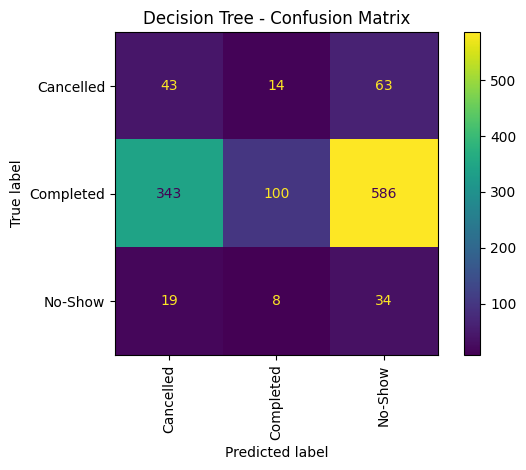

In [36]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions on the test dataset
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.2%}")

# Show precision, recall, and F1-score for each class
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

Why accuracy was poor-

Class imbalance: completed trips represent about 85% of the full dataset, while cancellations and no-shows are much less common.



Balanced class weights: we used class_weight="balanced", which encourages the model to pay more attention to the smaller classes. This can improve minority-class recall, but it can also increase incorrect predictions.



Weak predictive features: pickup time and location may not contain enough information to distinguish trip outcomes.



Questionable data quality: the city and coordinate inconsistencies remain unresolve


Compare against a simple baseline

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create a simple baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Train the baseline using the same training data
baseline.fit(X_train, y_train)

# Predict the test outcomes
baseline_pred = baseline.predict(X_test)

# Compare accuracies
print("Decision Tree accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))

print("\nBaseline classification report:")
print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))

Decision Tree accuracy: 0.1463
Baseline accuracy: 0.8504

Baseline classification report:
              precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00       120
   Completed       0.85      1.00      0.92      1029
     No-Show       0.00      0.00      0.00        61

    accuracy                           0.85      1210
   macro avg       0.28      0.33      0.31      1210
weighted avg       0.72      0.85      0.78      1210



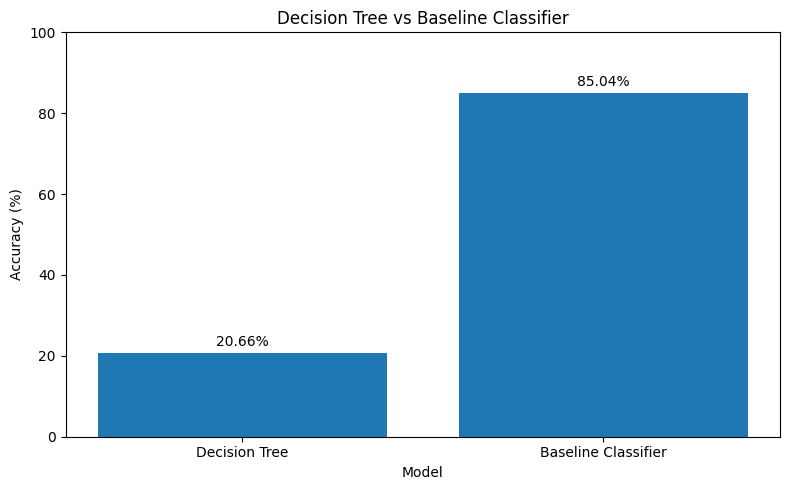

In [43]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

# Calculate the accuracy of each model
decision_tree_accuracy = accuracy_score(y_test, y_pred)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

# Prepare the chart
models = ["Decision Tree", "Baseline Classifier"]
accuracies = [
    decision_tree_accuracy * 100,
    baseline_accuracy * 100
]

# Draw the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

# Add accuracy percentages above the bars
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("Decision Tree vs Baseline Classifier")
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


Comparing against a simple baseline hase a useful comparison -
Baseline accuracy: 85.04% — it predicts Completed for every trip because that is the majority class.



Decision Tree accuracy: 14.63% — our current tree performs much worse than the baseline.



Important: the baseline’s high accuracy does not mean it is a good model. It completely fails to identify Cancelled and No-Show trips.


Adjusting the decision tree

In [38]:
# Train a Decision Tree without balanced class weights

model_no_balance = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

model_no_balance.fit(X_train, y_train)

# Make predictions
y_pred_no_balance = model_no_balance.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred_no_balance), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_no_balance, zero_division=0
))

Decision Tree Accuracy: 0.8479

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00       120
   Completed       0.85      1.00      0.92      1029
     No-Show       0.00      0.00      0.00        61

    accuracy                           0.85      1210
   macro avg       0.28      0.33      0.31      1210
weighted avg       0.72      0.85      0.78      1210



Checking the features the model is using

In [39]:
# Add distance and fare to the existing features
features = [
    "pickup_hour",
    "pickup_day",
    "pickup_lat",
    "pickup_lng",
    "drop_lat",
    "drop_lng",
    "distance_km",
    "fare_amount",
    "payment_method"
]

X = df[features].copy()
y = df["status"].copy()

# Split the data using the same settings
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the Decision Tree with balanced class weights
model = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"),
             ["payment_method"])
        ],
        remainder="passthrough"
    )),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Updated Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Updated Decision Tree Accuracy: 0.2066

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.08      0.28      0.13       120
   Completed       0.84      0.18      0.29      1029
     No-Show       0.06      0.56      0.10        61

    accuracy                           0.21      1210
   macro avg       0.33      0.34      0.18      1210
weighted avg       0.73      0.21      0.27      1210



Trying random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"),
             ["payment_method"])
        ],
        remainder="passthrough"
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, rf_pred, zero_division=0
))

Random Forest Accuracy: 0.5165

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.10      0.21      0.13       120
   Completed       0.84      0.57      0.68      1029
     No-Show       0.06      0.25      0.10        61

    accuracy                           0.52      1210
   macro avg       0.33      0.34      0.30      1210
weighted avg       0.73      0.52      0.59      1210



Let's test Random Forest without balanced class weights.

In [41]:
rf_model_unbalanced = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"),
             ["payment_method"])
        ],
        remainder="passthrough"
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_model_unbalanced.fit(X_train, y_train)

rf_pred_unbalanced = rf_model_unbalanced.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred_unbalanced), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, rf_pred_unbalanced, zero_division=0
))

Random Forest Accuracy: 0.8504

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00       120
   Completed       0.85      1.00      0.92      1029
     No-Show       0.00      0.00      0.00        61

    accuracy                           0.85      1210
   macro avg       0.28      0.33      0.31      1210
weighted avg       0.72      0.85      0.78      1210



Check whether the model has learned anything useful

In [42]:
print("Actual test-set class counts:")
print(y_test.value_counts())

print("\nBalanced Random Forest predictions:")
print(pd.Series(rf_pred, name="Predicted status").value_counts())

Actual test-set class counts:
status
Completed    1029
Cancelled     120
No-Show        61
Name: count, dtype: int64

Balanced Random Forest predictions:
Predicted status
Completed    697
Cancelled    260
No-Show      253
Name: count, dtype: int64


## 5. Comparison of Models

| Model | Accuracy | Macro F1-score | Main finding |
|---|---:|---:|---|
| Most-frequent baseline | 85.04% | 0.31 | Predicts only Completed |
| Balanced Decision Tree, initial features | 14.63% | 0.14 | Very poor overall performance |
| Balanced Decision Tree, extra features | 20.66% | 0.18 | Identifies some minority-class trips |
| Unbalanced Decision Tree | 84.79% | 0.31 | Fails to identify minority classes |
| Balanced Random Forest | 51.65% | 0.30 | Identifies all classes but makes many errors |
| Unbalanced Random Forest | 85.04% | 0.31 | Predicts only Completed |

The comparison indicates that no tested model has yet provided a convincing improvement over the baseline. Macro F1-score is particularly useful here because it gives equal importance to the performance on each class rather than allowing the dominant Completed class to determine the overall result.

The models and their evaluation results should be treated as preliminary findings, not as evidence of a production-ready prediction system.

# 6. Limitations and Further Validation

## 6.1 Limitations

Several limitations affect the reliability and usefulness of the current experiment.

1. **Class imbalance:** Completed trips account for approximately 85% of the dataset. This makes it possible to achieve high accuracy without correctly identifying Cancelled and No-Show trips.

2. **Geographic inconsistency:** The city labels and pickup coordinates appear inconsistent. This could reduce the usefulness of location-related features.

3. **Target limitation:** The target variable represents historical trip status rather than ride-pooling compatibility. The models cannot determine whether two students have compatible routes or departure times.

4. **Feature limitations:** The available dataset does not contain explicit information about passenger route overlap, willingness to share, seat availability, or maximum acceptable detours.

5. **Validation limitations:** The models were evaluated using one stratified train/test split. Repeated stratified cross-validation would provide a more robust assessment of performance across different data splits.

## 6.2 Further Validation

Further work should compare the models using stratified cross-validation and examine the precision, recall, and macro F1-score for each class. A confusion matrix should also be used to identify which classes are being misclassified.

The geographic information should be verified before relying on coordinates for predictions. Any future model should also be compared with a baseline and evaluated on data that was not used during training.

For a genuine UniPool ride-pooling model, suitable data would need to identify compatible trips or successful shared rides. A separate model could then be developed to assess route similarity, departure-time compatibility, and detour constraints.

# 7. Conclusion

This experiment investigated supervised classification for predicting historical ride status using a sample trip dataset. A baseline classifier, Decision Tree, and Random Forest were trained and evaluated.

Although the baseline and unbalanced models achieved approximately 85% accuracy, they predicted only Completed trips and failed to identify Cancelled and No-Show trips. The balanced Random Forest identified examples from all three classes but achieved only 51.65% accuracy.

The findings demonstrate the importance of evaluating classification models using multiple metrics, particularly when classes are imbalanced. The experiment also identified potential data-quality issues and limitations in the target variable.

The current results are preliminary and do not establish that the models are suitable for real-world deployment. Further validation, improved data quality, and a dataset containing ride-pooling compatibility information would be necessary to develop a model that directly supports UniPool's primary objective.